In [29]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("cars.csv")
df.describe(percentiles=[]).T

,count,mean,std,min,50%,max
year,9694.0,2.001097e+03,1.107696e+01,1.980000e+03,2.002000e+03,2.018000e+03
product_id,9694.0,4.866750e+02,2.789975e+02,0.000000e+00,5.120000e+02,1.066000e+03
sales,9694.0,5.910339e+04,8.694025e+04,1.000000e+01,2.739400e+04,8.914820e+05
number_households,9694.0,1.072133e+08,1.393279e+07,8.078000e+07,1.093000e+08,1.275900e+08
price,9694.0,3.604769e+01,1.712656e+01,1.114478e+01,3.182023e+01,9.998639e+01
height,9694.0,6.094814e+01,8.411517e+00,4.350000e+01,5.770000e+01,1.075000e+02
footprint,9694.0,1.339263e+04,1.968915e+03,6.514540e+03,1.333006e+04,2.182186e+04
weight,9694.0,3.561211e+03,8.977655e+02,1.113000e+03,3.470500e+03,8.550000e+03
hp,9694.0,1.921820e+02,8.388244e+01,4.400000e+01,1.750000e+02,6.450000e+02
mpg,9694.0,2.093615e+01,6.583005e+00,1.000000e+01,1.900000e+01,5.000000e+01


## Opgave 1

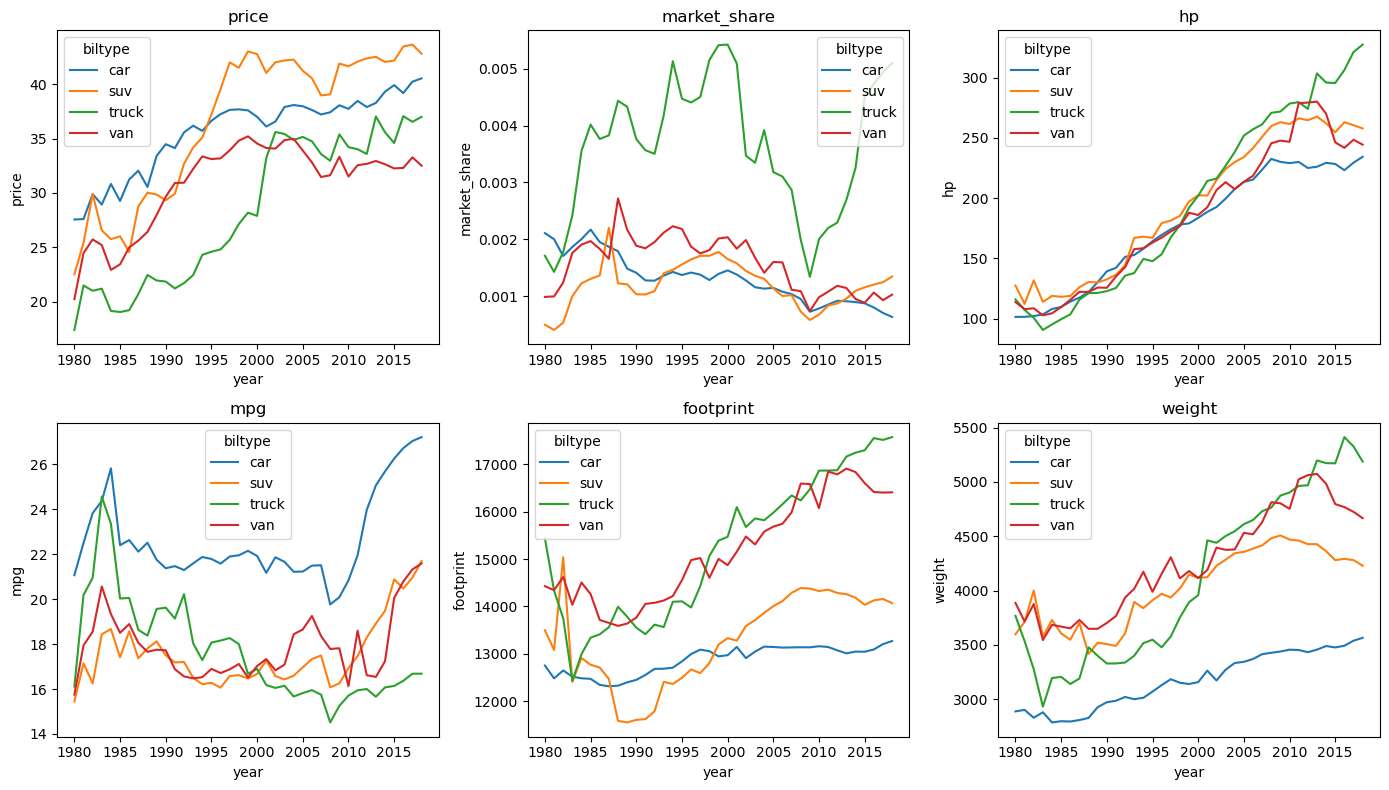

In [30]:
#A
car_types = ['car', 'suv', 'truck', 'van']

df_long = df.melt(
    id_vars=['year', 'price', 'market_share', 'hp', 'mpg', 'footprint', 'weight'],
    value_vars=car_types,
    var_name='biltype',
    value_name='type_dummy'
)

df_long = df_long[df_long['type_dummy'] == 1]

variables = ['price', 'market_share', 'hp', 'mpg', 'footprint', 'weight']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for var, ax in zip(variables, axes.ravel()):
    sns.lineplot(
        data=df_long,
        x='year',
        y=var,
        hue='biltype',
        errorbar=None,
        ax=ax
    )
    ax.set_title(var)

plt.tight_layout()
plt.show()


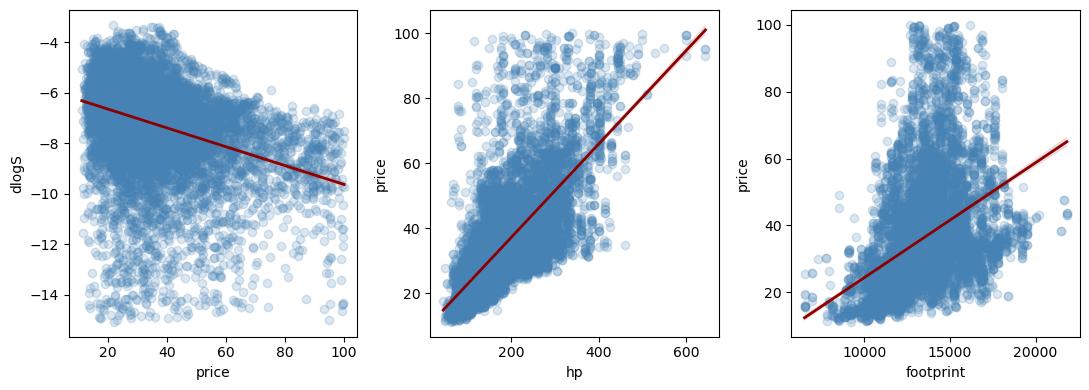

In [31]:
#A
fig, axes = plt.subplots(1, 3, figsize=(11, 4))

sns.regplot(
    data=df,
    x='price',
    y='dlogS',
    scatter_kws={
        'alpha': 0.2,
        'color': 'steelblue'
    },
    line_kws={
        'color': 'darkred',
        'linewidth': 2
    },
    ax=axes[0]
)

sns.regplot(
    data=df,
    x='hp',
    y='price',
    scatter_kws={
        'alpha': 0.2,
        'color': 'steelblue'
    },
    line_kws={
        'color': 'darkred',
        'linewidth': 2
    },
    ax=axes[1]
)


sns.regplot(
    data=df,
    x='footprint',
    y='price',
    scatter_kws={
        'alpha': 0.2,
        'color': 'steelblue'
    },
    line_kws={
        'color': 'darkred',
        'linewidth': 2
    },
    ax=axes[2]
)
plt.tight_layout()
plt.show()

## Opgave 2

In [ ]:
#B
specifikation1 

## Opgave 3

## Opgave 4
### 4C

In [32]:

# Generel simulationsfunktion
def simulate(n, gamma1, gamma2):
    # Parametre
    beta0 = 0.5
    beta1 = -0.1
    gamma0 = 0.25

    # Simulér z og fejlled
    v = np.random.normal(loc=0, scale=1, size=n)
    z = np.random.normal(loc=0, scale=1, size=n)
    xi = np.random.normal(loc=0, scale=1, size=n)

    # Reduceret form for prisen
    eta0 = (gamma0 - beta0) / (beta1 - gamma1)
    eta1 = gamma2 / (beta1 - gamma1)
    u = (v - xi) / (beta1 - gamma1)

    p = eta0 + eta1*z + u

    # Efterspørgselsligningen
    y = beta0 + beta1*p + xi

    # Naiv OLS
    X = pd.DataFrame({'p': p})
    X = sm.add_constant(X)

    model_ols = sm.OLS(y, X)
    results_ols = model_ols.fit()

    beta1_ols = results_ols.params['p']

    # IV/2SLS: første trin
    Z = pd.DataFrame({'z': z})
    Z = sm.add_constant(Z)

    first_stage = sm.OLS(p, Z).fit()
    p_hat = first_stage.fittedvalues

    # IV/2SLS: andet trin
    X_iv = pd.DataFrame({'p_hat': p_hat})
    X_iv = sm.add_constant(X_iv)

    iv_results = sm.OLS(y, X_iv).fit()
    beta1_iv = iv_results.params['p_hat']

    return {
        'beta1_OLS': beta1_ols,
        'beta1_IV': beta1_iv
    }


def monte_carlo(reps, n, gamma1, gamma2):
    np.random.seed(0)

    simulationer = []

    for rep in range(reps):
        resultat = simulate(n, gamma1, gamma2)
        simulationer.append(resultat)

    return pd.DataFrame(simulationer)


results_1 = monte_carlo(reps=500, n=500, gamma1=1, gamma2=1)
results_2 = monte_carlo(reps=500, n=500, gamma1=1, gamma2=0.25)
results_3 = monte_carlo(reps=500, n=500, gamma1=0.25, gamma2=1)

def make_table(results):
    return pd.DataFrame({
        'OLS': [
            results['beta1_OLS'].mean(),
            results['beta1_OLS'].std()
        ],
        'IV': [
            results['beta1_IV'].mean(),
            results['beta1_IV'].std()
        ]
    }, index=[
        'Middelværdi af beta1_hat',
        'Standardafvigelse af beta1_hat'
    ])


print("Scenarie 1: gamma1 = 1, gamma2 = 1")
print(make_table(results_1).round(4))
print("Scenarie 2: gamma1 = 1, gamma2 = 0.25")
print(make_table(results_2).round(4))
print("Scenarie 3: gamma1 = 0.25, gamma2 = 1")
print(make_table(results_3).round(4))

Scenarie 1: gamma1 = 1, gamma2 = 1
                                   OLS      IV
Middelværdi af beta1_hat        0.2670 -0.1016
Standardafvigelse af beta1_hat  0.0234  0.0497
Scenarie 2: gamma1 = 1, gamma2 = 0.25
                                   OLS      IV
Middelværdi af beta1_hat        0.4347 -0.1382
Standardafvigelse af beta1_hat  0.0247  0.2350
Scenarie 3: gamma1 = 0.25, gamma2 = 1
                                   OLS      IV
Middelværdi af beta1_hat        0.0168 -0.1005
Standardafvigelse af beta1_hat  0.0075  0.0158
